# 04. SHAP 해석 — 어떤 센서를 먼저 점검할까

PROTOCOL.md 8절. **학습 데이터만** 사용한다. 최종 평가 이후의 분석이라 앞의 결정을 바꾸지 않는다.

최종 평가에서 두 모델 모두 무작위와 통계적으로 구분되지 않았다. 그래서 이 결과는 **불량 원인이 아니라 엔지니어가 먼저 확인해 볼 후보**로 다룬다.
후보의 신뢰도를 판단하려고 세 가지를 같이 본다.

1. 두 모델(작동 방식이 전혀 다름)이 같은 센서를 짚는가
2. 학습 기간을 바꿔도 순위가 유지되는가
3. 같은 달 안에서도 관계가 보이는가 (시기 효과가 아닌가)

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from src.data import load_train
from src.interpret import shap_frame, correlation_groups, group_names, group_importance

sns.set_theme(style="whitegrid")
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
X, y, ts = load_train()
decisions = json.loads((REPORT_DIR / "best_params.json").read_text())
LABELS = {"logistic": "로지스틱 회귀", "lightgbm": "LightGBM"}

## 1. SHAP 값 계산

SHAP은 예측 하나를 센서별 기여도로 나눈다. 값이 양수면 그 센서가 불량 쪽으로, 음수면 정상 쪽으로 밀었다는 뜻이다.
센서별 중요도는 **SHAP 절댓값의 평균**(얼마나 자주, 크게 예측을 움직였나)으로 본다.

In [2]:
shap_values = {name: shap_frame(name, d["params"], X, y, X) for name, d in decisions.items()}
raw_top = pd.DataFrame({
    LABELS[n]: S.abs().mean().sort_values(ascending=False).head(10).index.str.replace("sensor_", "s")
    for n, S in shap_values.items()
}, index=range(1, 11))
raw_top

,로지스틱 회귀,LightGBM
1,s059,s059
2,s341,s460
3,s000,s000
4,s205,s129
5,s477,s033
6,s460,s519
7,s129,s247
8,s333,s125
9,s488,s130
10,s103,s175


**해석**: 묶기 전 순위에서 `s059`가 두 모델 모두 1위다. `s000`, `s129`, `s460`도 두 모델 상위 10위에 같이 들어 있다.

## 2. 쌍둥이 센서 묶기: 왜 순위 상관을 쓰나

EDA에서 191개 센서가 다른 센서와 |r| > 0.95였다. 쌍둥이 센서는 중요도를 나눠 가지므로 묶어서 봐야 한다.
그런데 일반 상관(피어슨)으로 묶으면 **오류값 때문에 잘못 묶이는** 그룹이 생긴다.

In [3]:
g = ["sensor_067", "sensor_204", "sensor_205", "sensor_340"]
glitch = (X[g] > 100).any(axis=1)
print(f"오류값(>100)이 있는 행: {int(glitch.sum())}개")
comp = pd.DataFrame({
    "피어슨 (전체)": X[g].corr().loc["sensor_067", g[1:]],
    "피어슨 (오류값 4행 제외)": X.loc[~glitch, g].corr().loc["sensor_067", g[1:]],
    "스피어만 (전체)": X[g].corr(method="spearman").loc["sensor_067", g[1:]],
}).round(2)
comp.index = [f"sensor_067 vs {c}" for c in comp.index]
comp

오류값(>100)이 있는 행: 4개


,피어슨 (전체),피어슨 (오류값 4행 제외),스피어만 (전체)
sensor_067 vs sensor_204,0.97,0.10,0.00
sensor_067 vs sensor_205,0.92,-0.01,0.01
sensor_067 vs sensor_340,0.97,0.12,0.02


**해석**: 피어슨으로는 sensor_067과 나머지가 0.9 이상이지만, 오류값 4행을 빼면 0.1 수준이다.
4개 행에서 동시에 9998 같은 값이 찍혀서 생긴 가짜 상관이다. 순위 상관(스피어만)은 값의 순서만 봐서 이런 영향을 받지 않는다.

→ 그룹은 **스피어만 |r| > 0.95**로 만든다. 계획서에 상관 종류가 정해져 있지 않아 PROTOCOL.md 변경 기록에 남겼다.

In [4]:
used = sorted({c for S in shap_values.values() for c in S.columns if not c.endswith("_isna")})
groups = correlation_groups(X[used])
sizes = groups.value_counts()
print(f"센서 {len(used)}개 → 그룹 {groups.nunique()}개 (2개 이상 묶인 그룹 {(sizes > 1).sum()}개, 가장 큰 그룹 {sizes.max()}개)")

센서 444개 → 그룹 291개 (2개 이상 묶인 그룹 99개, 가장 큰 그룹 6개)


## 3. 그룹 중요도

,로지스틱 회귀,LightGBM
1,s172+s174+s307+s309…,s059
2,s205+s341+s477,s460
3,s059,s247+s519
4,s175+s310+s446,s000
5,s197+s469,s129
6,s171+s306+s442,s175+s310+s446
7,s169+s304+s440,s033
8,s143+s416,s205+s341+s477
9,s177+s312+s448,s172+s174+s307+s309…
10,s152+s287+s425,s155+s290+s428


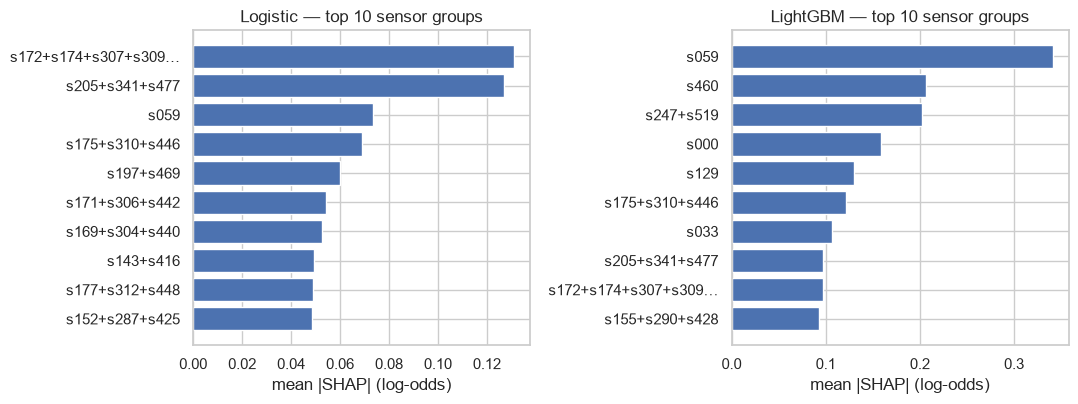

In [5]:
group_imp = {n: group_importance(S, groups) for n, S in shap_values.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (n, imp) in zip(axes, group_imp.items()):
    top = imp.head(10)[::-1]
    ax.barh(top.index, top.values, color="#4C72B0")
    ax.set_title({"logistic": "Logistic", "lightgbm": "LightGBM"}[n] + " — top 10 sensor groups")
    ax.set_xlabel("mean |SHAP| (log-odds)")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_shap_groups.png", dpi=150)

pd.DataFrame({LABELS[n]: imp.head(10).index for n, imp in group_imp.items()}, index=range(1, 11))

**해석**
- 그룹으로 묶으면 로지스틱 회귀의 순위가 바뀐다. 로지스틱은 L2 규제 때문에 쌍둥이 센서들에 가중치를 고르게 나눠 주므로, 큰 그룹이 합쳐지면서 위로 올라온다.
- LightGBM은 한 번에 센서 하나로 질문하므로 쌍둥이 중 하나만 쓰는 경향이 있어, 묶어도 순위가 크게 바뀌지 않는다.
- 두 모델 상위 10위에 공통으로 든 그룹은 `s059`, `s175+s310+s446`, `s205+s341+s477`, `s172+s174+…` 네 개다.

## 4. 기간을 바꿔도 순위가 유지되나

학습 기간 앞부분만으로 학습한 모델(교차검증 fold 2~4의 학습 구간)에서도 같은 그룹이 상위 10위에 드는지 본다.

In [6]:
prefixes = [tr for tr, _ in TimeSeriesSplit(4).split(X)][1:]
stability = {}
for n, d in decisions.items():
    top_full = list(group_imp[n].head(10).index)
    hits = pd.Series(0, index=top_full)
    for tr in prefixes:
        S_sub = shap_frame(n, d["params"], X.iloc[tr], y.iloc[tr], X.iloc[tr])
        top_sub = set(group_importance(S_sub, groups.loc[[c for c in groups.index if c in S_sub.columns]]).head(10).index)
        hits += [g in top_sub for g in top_full]
    stability[n] = hits

pd.DataFrame({LABELS[n]: [f"{g} ({h}/3)" for g, h in s.items()] for n, s in stability.items()}, index=range(1, 11))

,로지스틱 회귀,LightGBM
1,s172+s174+s307+s309… (2/3),s059 (2/3)
2,s205+s341+s477 (1/3),s460 (1/3)
3,s059 (2/3),s247+s519 (3/3)
4,s175+s310+s446 (3/3),s000 (3/3)
5,s197+s469 (1/3),s129 (0/3)
6,s171+s306+s442 (2/3),s175+s310+s446 (2/3)
7,s169+s304+s440 (3/3),s033 (1/3)
8,s143+s416 (3/3),s205+s341+s477 (2/3)
9,s177+s312+s448 (2/3),s172+s174+s307+s309… (1/3)
10,s152+s287+s425 (0/3),s155+s290+s428 (2/3)


**해석**: 괄호 안 숫자는 "앞부분만으로 학습한 모델 3개 중 몇 개에서도 상위 10위에 들었나"다.
3/3이면 기간이 바뀌어도 꾸준히 중요하게 쓰인 그룹이고, 0/3이면 마지막 학습 기간에만 중요했던 그룹이다.
- 전체적으로 순위가 많이 흔들린다. 불량 80개로 학습한 모델의 해석이 그만큼 불안정하다.
- `s175+s310+s446`은 두 모델에서 모두 꾸준하다(3/3, 2/3). `s059`도 두 모델 모두 2/3이다.
- 꾸준하다고 해서 믿을 만한 것은 아니다. `s247+s519`는 3/3이지만 아래 5절에서 보듯 시기를 대신하는 것으로 보인다. 시기 효과는 기간을 바꿔도 꾸준히 나타나기 때문이다.

## 5. 시기 효과인가, 센서 효과인가

EDA에서 불량률이 7월 22% → 9월 2.7%로 떨어졌다. 센서 값도 시기에 따라 변하면, 모델이 센서가 아니라 "시기"를 보고 있을 수 있다.

### 5-1. 결측이 시기를 대신하는 센서

In [7]:
S_gb = shap_values["lightgbm"]
rows = []
for c in ["sensor_519", "sensor_247"]:
    na = X[c].isna()
    rows.append({"sensor": c, "결측률": na.mean(),
                 "결측 행의 평균 SHAP": S_gb.loc[na, c].mean(), "값 있는 행의 평균 SHAP": S_gb.loc[~na, c].mean(),
                 "앞 절반 결측률": na.iloc[: len(X) // 2].mean(), "뒤 절반 결측률": na.iloc[len(X) // 2:].mean()})
pd.DataFrame(rows).set_index("sensor").round(3)

,결측률,결측 행의 평균 SHAP,값 있는 행의 평균 SHAP,앞 절반 결측률,뒤 절반 결측률
sensor,,,,,
sensor_519,0.323,-0.041,0.02,0.189,0.457
sensor_247,0.323,-0.021,0.01,0.189,0.457


**해석**: LightGBM은 이 센서들이 **비어 있으면 불량 확률을 낮춘다**. 그런데 이 센서들은 학습 기간 뒤쪽(불량이 적은 시기)에 더 자주 비어 있다.
모델이 센서 자체보다 "언제 만든 제품인가"를 읽고 있을 가능성이 크다. → **점검 후보에서 낮은 신뢰도**로 분류한다.

### 5-2. 같은 달 안에서도 관계가 유지되나

In [8]:
month = ts.dt.month
rows = []
for c in ["sensor_059", "sensor_175", "sensor_205", "sensor_129", "sensor_460", "sensor_000"]:
    row = {"sensor": c}
    for m in [8, 9]:
        idx = (month == m) & X[c].notna()
        terc = pd.qcut(X.loc[idx, c].rank(method="first"), 3, labels=["낮음", "중간", "높음"])
        rates = y[idx].groupby(terc).mean()
        row[f"{m}월 불량률 (낮음→높음)"] = " → ".join(f"{v:.1%}" for v in rates)
    rows.append(row)
within = pd.DataFrame(rows).set_index("sensor")
within

,8월 불량률 (낮음→높음),9월 불량률 (낮음→높음)
sensor,,
sensor_059,3.2% → 9.8% → 14.7%,0.5% → 1.6% → 5.9%
sensor_175,6.5% → 8.7% → 12.4%,1.1% → 3.2% → 3.8%
sensor_205,5.9% → 7.1% → 14.6%,1.6% → 2.2% → 4.3%
sensor_129,4.9% → 9.8% → 13.1%,0.5% → 3.8% → 3.8%
sensor_460,6.5% → 8.7% → 12.4%,0.5% → 4.9% → 2.7%
sensor_000,12.5% → 8.7% → 6.5%,4.3% → 1.6% → 2.2%


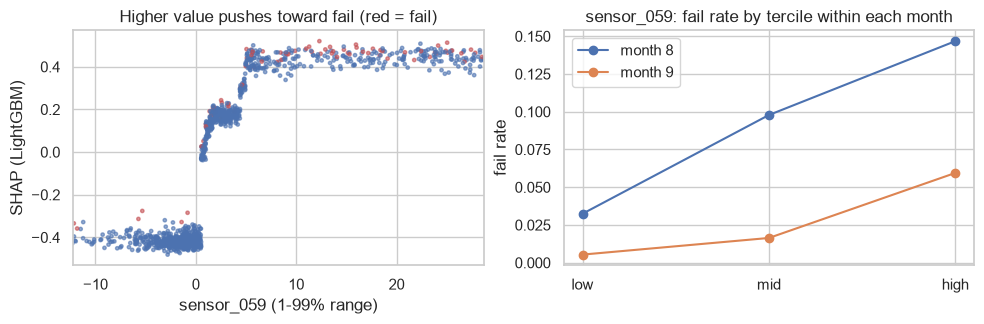

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
c = "sensor_059"
axes[0].scatter(X[c], S_gb[c], s=6, c=y.map({0: "#4C72B0", 1: "#C44E52"}), alpha=0.6)
axes[0].set_xlim(X[c].quantile(0.01), X[c].quantile(0.99))  # 극단값 몇 개 때문에 축이 늘어나지 않게
axes[0].set_xlabel(c + " (1-99% range)"); axes[0].set_ylabel("SHAP (LightGBM)"); axes[0].set_title("Higher value pushes toward fail (red = fail)")
for m, color in [(8, "#4C72B0"), (9, "#DD8452")]:
    idx = (month == m)
    terc = pd.qcut(X.loc[idx, c], 3, labels=["low", "mid", "high"])
    axes[1].plot(["low", "mid", "high"], y[idx].groupby(terc).mean().values, "o-", color=color, label=f"month {m}")
axes[1].set_ylabel("fail rate"); axes[1].set_title(f"{c}: fail rate by tercile within each month"); axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "11_sensor059.png", dpi=150)

**해석**
- `s059`, `s175`, `s205`는 **8월 안에서도, 9월 안에서도** 값이 높을수록 불량률이 높다. 시기를 고정해도 관계가 남는다.
- `s129`도 두 달 모두 낮은 쪽보다 높은 쪽의 불량률이 높다. 다만 9월에는 중간과 높음이 같다.
- `s460`은 8월에는 뚜렷하지만 9월에는 방향이 흔들린다. `s000`은 반대 방향(값이 낮을수록 불량)이고 9월에는 약하다.
- 9월 불량은 15개뿐이라 이 비교도 확정적이지 않다.

## 6. 정리: 점검 후보

| 후보 | 근거 | 신뢰도 |
|---|---|---|
| **s059** | 두 모델 공통 상위(LightGBM 1위). 같은 달 안에서도 값이 높을수록 불량률 상승 | 상대적으로 높음 |
| **s175+s310+s446** | 두 모델 공통 상위, 기간을 바꿔도 꾸준함. 같은 달 안에서도 s175가 높을수록 불량률 상승 | 상대적으로 높음 |
| **s205+s341+s477** | 두 모델 공통 상위. 같은 달 안에서도 s205가 높을수록 불량률 상승. 기간에 따라 순위는 흔들림 | 중간 |
| s129 | 두 모델 상위권. 같은 달 안에서도 대체로 같은 방향이지만, 기간을 바꾸면 상위권에서 빠짐(LightGBM 0/3) | 중간 |
| s000, s460 | 두 모델 상위권. 같은 달 안의 관계가 한 달에서만 뚜렷함 | 중간 |
| s247+s519 | LightGBM 상위권, 기간을 바꿔도 꾸준하지만 결측 여부가 시기를 대신하는 것으로 보임 | 낮음 |

**한계**
- 모델 성능이 무작위와 통계적으로 구분되지 않는다. SHAP은 "모델이 무엇을 봤나"를 보여줄 뿐 "무엇이 불량을 일으켰나"를 보여주지 않는다.
- 센서 이름이 익명이라 물리적 의미를 확인할 수 없다. 실제 현장이라면 s059가 어떤 장비·공정 단계의 무엇인지 확인하고, 해당 장비 로그를 보는 것이 다음 단계다.